# Adversarial examples - Blind spot in representation spaces
### Author: Pietro Gori

As for all TP, answer all questions and fill the code where you see **XXXXXXXXX**

**Deadline**: please verify on the Moodle/Ecampus/web site the deadline

In [1]:
import numpy as np
import random

# pytorch libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.autograd import Variable
from torch.utils.data import DataLoader, Dataset, TensorDataset

# torchvision
from torchvision import models, transforms
import torchvision.datasets as Data

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

%matplotlib inline

import time

In this practical session, you will produce adversarial examples using two strategies to analyse the quality and smoothness of a representation space. We will use the Mnist dataset and a simple network (with 97% accuracy on test though...) so that you can train and test on your own laptop. Same conclusions can be drawn by using larger architectures and more complex datasets (You can try if you want).

Let's start with the first method. Please read first the article [1], in particular from Sectioon 4. 

`[1] Szegedy, Christian, Zaremba, Wojciech, Sutskever, Ilya, Bruna, Joan, Erhan, Dumitru, Goodfellow, Ian J.,
and Fergus, Rob. Intriguing properties of neural networks. ICLR, 2014`

We first check if you are using a computer with GPU, CUDA (Nvidia) or MPS (MacBook), or only CPU. 

In [2]:
print("Using torch", torch.__version__)

if torch.backends.mps.is_available():
    device = torch.device("mps")
    x = torch.ones(1, device=device)
    print(x)
    print("MPS (MacBook) device found.")
    # print('Number of MPS cards: ', torch.mps.device_count())
    # print('Total MPS memory {0:.2f} GB'.format(torch.mps.recommended_max_memory()/pow(10,9)))
elif torch.backends.cuda.is_built() and torch.cuda.is_available():
    device = torch.device("cuda")
    x = torch.ones(1, device=device)
    print(x)
    print("CUDA device found.")
    print(
        "Number of GPU cards: ", torch.cuda.device_count(), "\nWhich card GPU?", torch.cuda.get_device_name(0)
    )
    print(
        "Total GPU memory {1:.2f} GB. Free GPU memory {0:.2f} GB".format(
            torch.cuda.mem_get_info()[0] / pow(10, 9), torch.cuda.mem_get_info()[1] / pow(10, 9)
        )
    )
else:
    device = torch.device("cpu")
    x = torch.ones(1, device=device)
    print(x)
    print("No MPS or CUDA has been found. PyTorch will use CPU.")

Using torch 2.8.0+cu128
tensor([1.])
No MPS or CUDA has been found. PyTorch will use CPU.


Here we fix the different seeds to make your algorithm reproducible and we set the hyper-parameters for the classification model we are going to train. You can modify them if you want, but I suggest you keep them like that for now and modify them only AFTER having trained for a first time the model. 

In [3]:
# to make the results reproducible
np.random.seed(10)
torch.manual_seed(10)
torch.cuda.manual_seed(10)
torch.mps.manual_seed(10)
random.seed(10)


# Parameters for training model
weight_decay = 1e-4
num_epochs = 5
batch_size = 256  # adapted to the Google Colab GPU
learning_rate = 0.001
loss_model = nn.CrossEntropyLoss()

We will use the MNIST dataset. Download it from torchvision.

In [4]:
mnist_train = Data.MNIST(root="data/", train=True, transform=transforms.ToTensor(), download=True)

train_loader = DataLoader(dataset=mnist_train, batch_size=batch_size, shuffle=True)

mnist_test = Data.MNIST(root="data/", train=False, transform=transforms.ToTensor(), download=True)

test_loader = DataLoader(dataset=mnist_test, batch_size=100, shuffle=False)

We analyse the data to check the number of samples and their size.

In [5]:
# Print infomration
print("There are ", len(mnist_train), "training images and ", len(mnist_test), "test images")
image_size = list(mnist_train[0][0].squeeze().shape)
print(f"Each image is of shape: {image_size}")  # [28, 28]


There are  60000 training images and  10000 test images
Each image is of shape: [28, 28]


Here we code the model proposed in the article. 

**Question**: complete the code so that you can create *A simple fully connected network with one or more hidden layers. We refer to this network as “FC”*. Please code it so that the input_size of the model (i.e. size of the input images), the number and size of hidden layers (e.g., [100,100]) and the output size (i.e., number of possible classes) are parameters of the model. Since we will use the Cross Entropy loss of Pytorch, the model should output the unnormalized logits for each class.

In [6]:
from torch.onnx.symbolic_caffe2 import relu


class FullyConnectedNet(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size):
        super(FullyConnectedNet, self).__init__()

        self.linears: list = nn.ModuleList([nn.Linear(input_size, hidden_sizes[0])])
        self.linears.extend(
            [nn.Linear(hidden_sizes[i], hidden_sizes[i + 1]) for i in range(len(hidden_sizes) - 1)],
        )
        self.linears.append(nn.Linear(hidden_sizes[-1], output_size))
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.flatten(start_dim=1)
        for f in self.linears[:-1]:
            x = f(x)
            x = self.relu(x)

        return self.linears[-1](x)

**Question**: Create one of the model proposed in the article.

In [7]:
input_size = 28 * 28
hidden_sizes = [256, 256]
output_size = 10


# Model
model = FullyConnectedNet(input_size, hidden_sizes, output_size).to(device)
# Optimizer
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

# Print the model
print(model)

FullyConnectedNet(
  (linears): ModuleList(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): Linear(in_features=256, out_features=256, bias=True)
    (2): Linear(in_features=256, out_features=10, bias=True)
  )
  (relu): ReLU()
)


Here we code the training procedure, as commonly done with Pytorch. Please note that we use the Adam optimizer.

In [8]:
def training(model, train_loader, optimizer, num_epochs, loss_model):
    for epoch in range(num_epochs):
        model.train()
        for i, (images, labels) in enumerate(train_loader):
            # Put images to GPU
            X = images.to(device)
            Y = labels.to(device)

            # Forward pass
            outputs = model(X)
            loss = loss_model(outputs, Y)

            # Backward and optimize
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            if (i + 1) % 100 == 0:
                print(
                    f"Epoch [{epoch + 1}/{num_epochs}], Step [{i + 1}/{len(train_loader)}], Loss: {loss.item():.4f}"
                )

And we evaluate it.

In [9]:
def evaluation(model, test_loader):
    model.eval()

    correct = 0
    total = 0

    for images, labels in test_loader:
        X = images.to(device)
        Y = labels.to(device)

        outputs = model(X)  # array of size [num test images, num classes]

        predicted_class = torch.argmax(outputs.data, dim=1)  # faster

        total += len(Y)
        correct += (predicted_class == Y).sum()

    print("Accuracy of test images: %f %%" % (100 * float(correct) / total))

In [10]:
# Training loop
training(model, train_loader, optimizer, num_epochs, loss_model)

Epoch [1/5], Step [100/235], Loss: 0.3416
Epoch [1/5], Step [200/235], Loss: 0.2447
Epoch [2/5], Step [100/235], Loss: 0.2117
Epoch [2/5], Step [200/235], Loss: 0.1015
Epoch [3/5], Step [100/235], Loss: 0.0742
Epoch [3/5], Step [200/235], Loss: 0.1251
Epoch [4/5], Step [100/235], Loss: 0.0499
Epoch [4/5], Step [200/235], Loss: 0.0744
Epoch [5/5], Step [100/235], Loss: 0.0593
Epoch [5/5], Step [200/235], Loss: 0.0617


In [11]:
evaluation(model, test_loader)

Accuracy of test images: 97.520000 %


**Question**: Is the performance good ? Test different architectures (number and size of hidden layers). You can also try different hyper-parameters (weight decay, number of epochs, etc.). Use the "Occam's razor principle" to choose and justify your final model. 

<font color='green'>
After some different experiments, I decided to keep the 2 layer network and to just increase the hidden size. I also added some weight decay.
</font>

Here, you will code the method proposed in Sec. 4.1 of [1]. I copy/paste it here:

We denote by $f : R^m \rightarrow {1 . . . k}$ a classifier mapping image pixel value vectors to a discrete label set. We also assume that $f$ has an associated continuous loss function denoted by $\text{loss}_f : R^m × {1 . . . k} \rightarrow R^+$. For a given $x \in R^m$ image and target label $l \in {1 . . . k}$, we aim to solve the following box-constrained optimization problem:

• Minimize $||r||_2$ subject to:
1. $f(x + r) = l$
2. $x + r \in [0, 1]^m$


The minimizer $r$ might not be unique, but we denote one such $x + r$ for an arbitrarily chosen minimizer by $D(x, l)$. Informally, $x + r$ is the closest image to $x$ classified as $l$ by $f$. Obviously, $D(x, f(x)) = f(x)$, so this task is non-trivial only if $f(x) \neq l$. In general, the exact computation
of $D(x, l)$ is a hard problem, so we approximate it by using a box-constrained L-BFGS. Concretely, we find an approximation of $D(x, l)$ by performing line-search to find the minimum $c > 0$ for which the minimizer $r$ of the following problem satisfies $f(x + r) = l$.

• Minimize $c|r| + \text{loss}_f (x + r, l)$ subject to $x + r \in [0, 1]^m$

This penalty function method would yield the exact solution for $D(X, l)$ in the case of convex losses, however neural networks are non-convex in general, so we end up with an approximation in this case.

We start by setting the hyper-parameters of the L-BFGS method. Keep them like that for now. You will come back later to change them.

In [12]:
# Parameters adversarial example
index = 666  # index test image to use

max_iter_search = 300
initial_c = 0.000001  # Initial value of c
max_c = 0.01  # Upper limit for c
mult_c = 1.03  # Multiplicative update of c at each iter c *= mult_c

epsilon_LBFGS = 1e-6  # Small value for line search stopping criterion
max_iter_LBFGS = 100  # Maximum iterations for L-BFGS
lr_LBFGS = 0.1  # Learning rate for L-BFGS

We can plot the chosen image

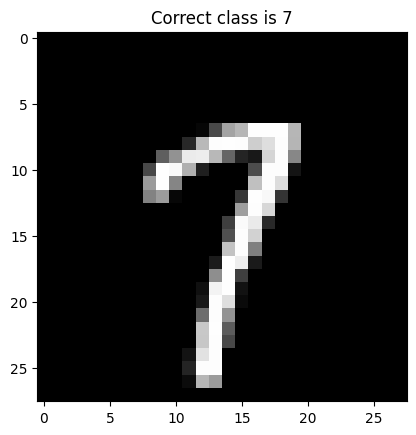

In [13]:
testI, testY = mnist_test.__getitem__(index)
fig = plt.imshow(testI.squeeze(), interpolation="nearest", cmap=plt.cm.gray)
plt.title(f"Correct class is {testY}")
plt.show()

I have written a code to plot the original image $x$, the modified image $x+r$ and the residual added $r$.

In [14]:
def plot_results(X, r, Xr, Y, l, fail=True):
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(25, 7))
    im1 = axes[0].imshow(X.squeeze().cpu().detach().numpy(), interpolation="nearest", cmap=plt.cm.gray)
    axes[0].set_title(f"Original Image. Correct class is {Y}", fontsize=22)

    im3 = axes[2].imshow(r.squeeze().cpu().detach().numpy(), interpolation="nearest", cmap=plt.cm.gray)
    axes[2].set_title(f"Residual added", fontsize=22)

    if fail:
        im2 = axes[1].imshow(Xr.squeeze().cpu().detach().numpy(), interpolation="nearest", cmap=plt.cm.gray)
        axes[1].set_title(f"Modified Image, FAILED to predict class {l.item()}", fontsize=22)
    else:
        im2 = axes[1].imshow(Xr.squeeze().cpu().detach().numpy(), interpolation="nearest", cmap=plt.cm.gray)
        axes[1].set_title(f"Modified Image, PREDICTED class {l.item()}", fontsize=22)

    # Add a single colorbar for all subplots
    cbar = fig.colorbar(im3, ax=axes, orientation="vertical", fraction=0.02, pad=0.04)
    cbar.set_label("Intensity (0 to 1)")

    # Show the plots
    plt.show()

Here we will code the proposed method. Complete the code where you see `XXXXXXX`.

Please be advised that the `torch.optim.LBFGS` optimizer is designed to work with a `closure` for computing the loss and gradients multiple times during optimization, which is essential for second-order methods.

The closure is a callable function passed to LBFGS that recomputes the loss and its gradients multiple times during a single optimization step.
To work correctly, we need to call `optimizer.zero_grad()` to clear old gradients before calculating new ones.

Please note that SGD or Adam don't require a closure because they update the parameters based on the current gradient in a single step.

More info here: https://pytorch.org/docs/stable/optim.html

The true class is 7, the new class will be 9
Found c = 0.000001 satisfying f(x + r) = l
Optimization succeeded with c = 0.000001 in 1 iterations
Norm Perturbation |r|: 29.449928283691406


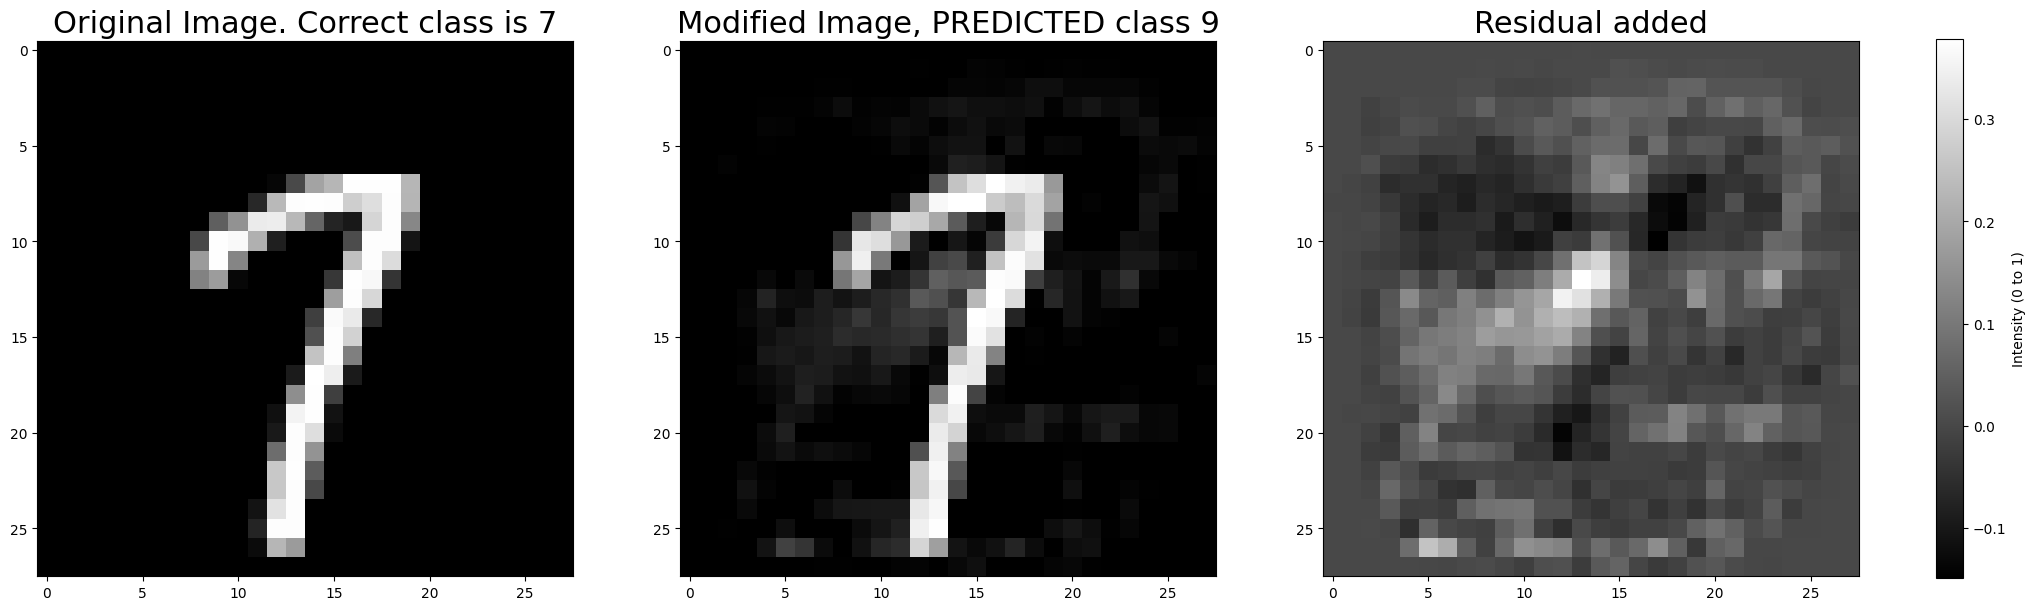

In [15]:
testI = testI.to(device)
r = torch.zeros_like(testI, requires_grad=True, device=device)  # Initialize r as zero
label = 9  # manually chosen target class label different from true one
l = torch.tensor([label]).to(device)
l = l.to(device)
l = l.view(1)  # to have a batch size equal to 1 and work with CrossEntropy loss
print(f"The true class is {testY}, the new class will be {l[0]}")


# Define the loss function
def objective(c, r, x, l):
    x_r = torch.clamp(x + r, 0, 1)
    logits = model(x_r)

    target = logits[0, l]
    others = torch.cat([logits[0, :l], logits[0, l + 1 :]])
    loss_cls = torch.clamp(others.max() - target, min=0)

    loss_reg = torch.norm(r, p=2)
    return c * loss_reg + loss_cls


# Line search to find the minimum c > 0
c = initial_c
iter = 0
while (c <= max_c) and (iter <= max_iter_search):
    # Define the optimizer (Box-Constrained L-BFGS)
    optimizerLBFGS = optim.LBFGS(
        [r],
        max_iter=50,
        line_search_fn="strong_wolfe",
    )

    def closure():
        optimizerLBFGS.zero_grad()
        loss = objective(c, r, testI, l)
        loss.backward()
        return loss

    # Perform optimization
    optimizerLBFGS.step(closure)

    # Evaluate the condition f(x + r) = l
    with torch.no_grad():
        x_r = torch.clamp(testI + r, 0, 1)  # Ensure x + r ∈ [0, 1]^m
        pred = model(x_r)
        predicted_label = torch.argmax(pred, dim=1)

    # Check if the condition f(x + r) = l is satisfied
    if predicted_label == l:
        print(f"Found c = {c:.6f} satisfying f(x + r) = l")
        iter = iter + 1
        break
    else:
        iter = iter + 1

    # If not satisfied, increase c
    c = c * 10  # Adjust step size for line search
    if (iter) % 20 == 0:
        print(f"Iter {iter}/{max_iter_search}, Value of c: {c:.6f}")

if (c > max_c) or (iter > max_iter_search):
    print("Failed to find c satisfying f(x + r) = l within the maximum limit of c and max number of iter.")
    # print(f"Perturbation r: {r}")
    print(f"Norm Perturbation |r|: {torch.norm(r, p=1)}")

    plot_results(testI, r, x_r, testY, l, fail=True)

else:
    print(f"Optimization succeeded with c = {c:.6f} in {iter} iterations")
    # print(f"Perturbation r: {r}")
    print(f"Norm Perturbation |r|: {torch.norm(r, p=1)}")

    plot_results(testI, r, x_r, testY, l, fail=False)

**QUESTION** Try with different images and different predicted classes (l), does the algorithm always converge ? You can test with different hyper-parameters for c. When it converges, are the images semantically similar to the original one ? Visually, would you say that they should belong to the original or new class ? What's the average distortion (norm of r) ? Would you prefer a small or large value of `c`? Why ? 

In [16]:
def batch_attack_stats(test_loader, model, targets, c, max_iter=20):
    succes, distortions, total = 0, [], 0

    for X, Y in test_loader:
        X, Y = X.to(device), Y.to(device)
        B = X.size(0)

        for l in targets:
            mask = Y != l
            if mask.sum() == 0:
                continue

            X_sel = X[mask]
            Y_sel = Y[mask]
            r = torch.zeros_like(X_sel, requires_grad=True)

            optimizer = torch.optim.LBFGS([r], max_iter=max_iter)

            def closure():
                optimizer.zero_grad()
                x_r = torch.clamp(X_sel + r, 0, 1)
                logits = model(x_r)

                target = logits[:, l]
                others = logits.clone()
                others[:, l] = -1e9
                loss_cls = torch.clamp(others.max(dim=1).values - target, min=0).mean()

                loss = c * torch.norm(r, p=2) + loss_cls
                loss.backward()
                return loss

            optimizer.step(closure)

            with torch.no_grad():
                preds = model(torch.clamp(X_sel + r, 0, 1)).argmax(dim=1)

            succes += (preds == l).sum().item()
            total += X_sel.size(0)
            distortions.append(torch.norm(r, p=2).item())

        break  # one batch is enough for lab

    return succes / total, sum(distortions) / len(distortions)


targets = [1, 3, 5, 7, 9]
c_values = [1e-3, 1e-2, 1e-1, 1.0]

for c in c_values:
    sr, d = batch_attack_stats(test_loader, model, targets, c)
    print(f"c={c:.0e} | success rate={100 * sr:.1f}% | avg ||r||₂={d:.3f}")


/home/fotis/MVA/RepLear/.venv/lib/python3.9/site-packages/torch/optim/lbfgs.py:457: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  loss = float(closure())


c=1e-03 | success rate=57.2% | avg ||r||₂=46087.155
c=1e-02 | success rate=19.2% | avg ||r||₂=inf
c=1e-01 | success rate=51.1% | avg ||r||₂=33328711347880.789
c=1e+00 | success rate=3.6% | avg ||r||₂=86318.603


<font color='green'>

The algorithm does not always converge, and its behavior is highly sensitive to the choice of the regularization parameter 
While small values of increase the success rate, they lead to excessively large perturbations, resulting in images that are neither semantically nor visually similar to the original. Larger values of  enforce small perturbations but often prevent convergence.
</font>

**Question** What if you try with different networks ? Test with al least another network (i.e., change hidden_sizes) and see if the previous conclusions are still confirmed. 

Furthermore, check the cross-network performance. This means:
- produce a set of adversarial instances for a given network (samples that are visually similar to the original class but recognised by the network as belonging to a different class)
- check if these adversarial examples are also wrongly classified by the other network

Which conclusions can you draw from these results ? Please comment on that.

In [17]:
input_size = 28 * 28
hidden_sizes = [100, 100, 50]
output_size = 10


# Model
model2 = FullyConnectedNet(input_size, hidden_sizes, output_size).to(device)
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

training(model, train_loader, optimizer, num_epochs, loss_model)

Epoch [1/5], Step [100/235], Loss: 0.0630
Epoch [1/5], Step [200/235], Loss: 0.0434
Epoch [2/5], Step [100/235], Loss: 0.0433
Epoch [2/5], Step [200/235], Loss: 0.0729
Epoch [3/5], Step [100/235], Loss: 0.0807
Epoch [3/5], Step [200/235], Loss: 0.0068
Epoch [4/5], Step [100/235], Loss: 0.0094
Epoch [4/5], Step [200/235], Loss: 0.0173
Epoch [5/5], Step [100/235], Loss: 0.0126
Epoch [5/5], Step [200/235], Loss: 0.0325


In [18]:
targets = [1, 3, 5, 7, 9]
c_values = [1e-3, 1e-2, 1e-1, 1.0]

for c in c_values:
    sr, d = batch_attack_stats(test_loader, model, targets, c)
    print(f"c={c:.0e} | success rate={100 * sr:.1f}% | avg ||r||₂={d:.3f}")


c=1e-03 | success rate=37.8% | avg ||r||₂=738825987005.058
c=1e-02 | success rate=53.4% | avg ||r||₂=inf
c=1e-01 | success rate=56.8% | avg ||r||₂=488331202369988.812
c=1e+00 | success rate=3.4% | avg ||r||₂=2095589202333.221


<font color='green'>
Changing the network architecture modifies the quantitative results (success rate and distortion levels), but the same qualitative behavior is observed: the attack does not always converge, remains highly sensitive to the parameter (c), and still exhibits a trade-off between attack success and perturbation magnitude.

</font>

In [19]:
input_size = 28 * 28
output_size = 10

# Model A
hidden_sizes_A = [100, 100]
modelA = FullyConnectedNet(input_size, hidden_sizes_A, output_size).to(device)
optimizerA = optim.Adam(modelA.parameters(), lr=learning_rate, weight_decay=weight_decay)
training(modelA, train_loader, optimizerA, num_epochs, loss_model)

# Model B
hidden_sizes_B = [100, 100, 50]
modelB = FullyConnectedNet(input_size, hidden_sizes_B, output_size).to(device)
optimizerB = optim.Adam(modelB.parameters(), lr=learning_rate, weight_decay=weight_decay)
training(modelB, train_loader, optimizerB, num_epochs, loss_model)


def generate_adversarial(model, x, y, target_label, initial_c, max_c, max_iter_search):
    r = torch.zeros_like(x, requires_grad=True, device=device)
    l = torch.tensor([target_label], device=device)

    def objective(c, r, x, l):
        x_r = torch.clamp(x + r, 0, 1)
        logits = model(x_r)
        target = logits[0, l]
        others = torch.cat([logits[0, :l], logits[0, l + 1 :]])
        loss_cls = torch.clamp(others.max() - target, min=0)
        loss_reg = torch.norm(r, p=2)
        return c * loss_reg + loss_cls

    c = initial_c
    it = 0
    success = False

    while c <= max_c and it <= max_iter_search:
        optimizer = optim.LBFGS([r], max_iter=50, line_search_fn="strong_wolfe")

        def closure():
            optimizer.zero_grad()
            loss = objective(c, r, x, l)
            loss.backward()
            return loss

        optimizer.step(closure)

        with torch.no_grad():
            pred = model(torch.clamp(x + r, 0, 1)).argmax(dim=1)

        if pred.item() == target_label:
            success = True
            break

        c *= 10
        it += 1

    return success, r, c


targets = [1, 3, 5, 7, 9]
initial_c = 1e-4
max_c = 1e1
max_iter_search = 20

transfer_success = 0
source_success = 0
total = 0

for X_batch, Y_batch in test_loader:
    for X, Y in zip(X_batch, Y_batch):
        X = X.unsqueeze(0).to(device)
        Y = Y.to(device)

        for l in targets:
            if l == Y.item():
                continue

            ok, r, c_found = generate_adversarial(modelA, X, Y, l, initial_c, max_c, max_iter_search)

            if not ok:
                continue

            source_success += 1

            with torch.no_grad():
                X_adv = torch.clamp(X + r, 0, 1)
                pred_B = modelB(X_adv).argmax(dim=1)

            if pred_B.item() == l:
                transfer_success += 1

            total += 1

    break  # one batch is sufficient

print(f"Adversarial success on model A: {100 * source_success / total:.1f}%")
print(f"Transfer success to model B:    {100 * transfer_success / total:.1f}%")


Epoch [1/5], Step [100/235], Loss: 0.3456
Epoch [1/5], Step [200/235], Loss: 0.3248
Epoch [2/5], Step [100/235], Loss: 0.2832
Epoch [2/5], Step [200/235], Loss: 0.1773
Epoch [3/5], Step [100/235], Loss: 0.1732
Epoch [3/5], Step [200/235], Loss: 0.1690
Epoch [4/5], Step [100/235], Loss: 0.1546
Epoch [4/5], Step [200/235], Loss: 0.1012
Epoch [5/5], Step [100/235], Loss: 0.1534
Epoch [5/5], Step [200/235], Loss: 0.0818
Epoch [1/5], Step [100/235], Loss: 0.4217
Epoch [1/5], Step [200/235], Loss: 0.2985
Epoch [2/5], Step [100/235], Loss: 0.2001
Epoch [2/5], Step [200/235], Loss: 0.1650
Epoch [3/5], Step [100/235], Loss: 0.1724
Epoch [3/5], Step [200/235], Loss: 0.1160
Epoch [4/5], Step [100/235], Loss: 0.1298
Epoch [4/5], Step [200/235], Loss: 0.1015
Epoch [5/5], Step [100/235], Loss: 0.1143
Epoch [5/5], Step [200/235], Loss: 0.1031
Adversarial success on model A: 100.0%
Transfer success to model B:    21.3%


<font color='green'>
The results show that adversarial examples generated for model A are highly effective on the source network, achieving a 100% attack success rate. However, when these same adversarial examples are evaluated on model B, the success rate drops to 29%, indicating limited transferability across architectures.
</font>

Instead than using L-BFGS to find adversarial examples we could also use a backpropagation method such as Adam, where you could optimize only r or both r and c. 

**Question** Change the previous code to use Adam instead than L-BFGS for the optimization. This means that you don't do anymore a line-search to find the minimum $c$ (no more closure). You can either fix $c$ and estimate only $r$ or estimate both. Try these two solutions and comment on that. Does it work properly ? If not, try to change the loss function. Would you add a regularization term ? If yes, which one and why ? Does it work better ? Would you minimize or maximize c ? Please comment on that. 

Predicted label: 9
||r||₂ = tensor(2.5066, grad_fn=<LinalgVectorNormBackward0>)


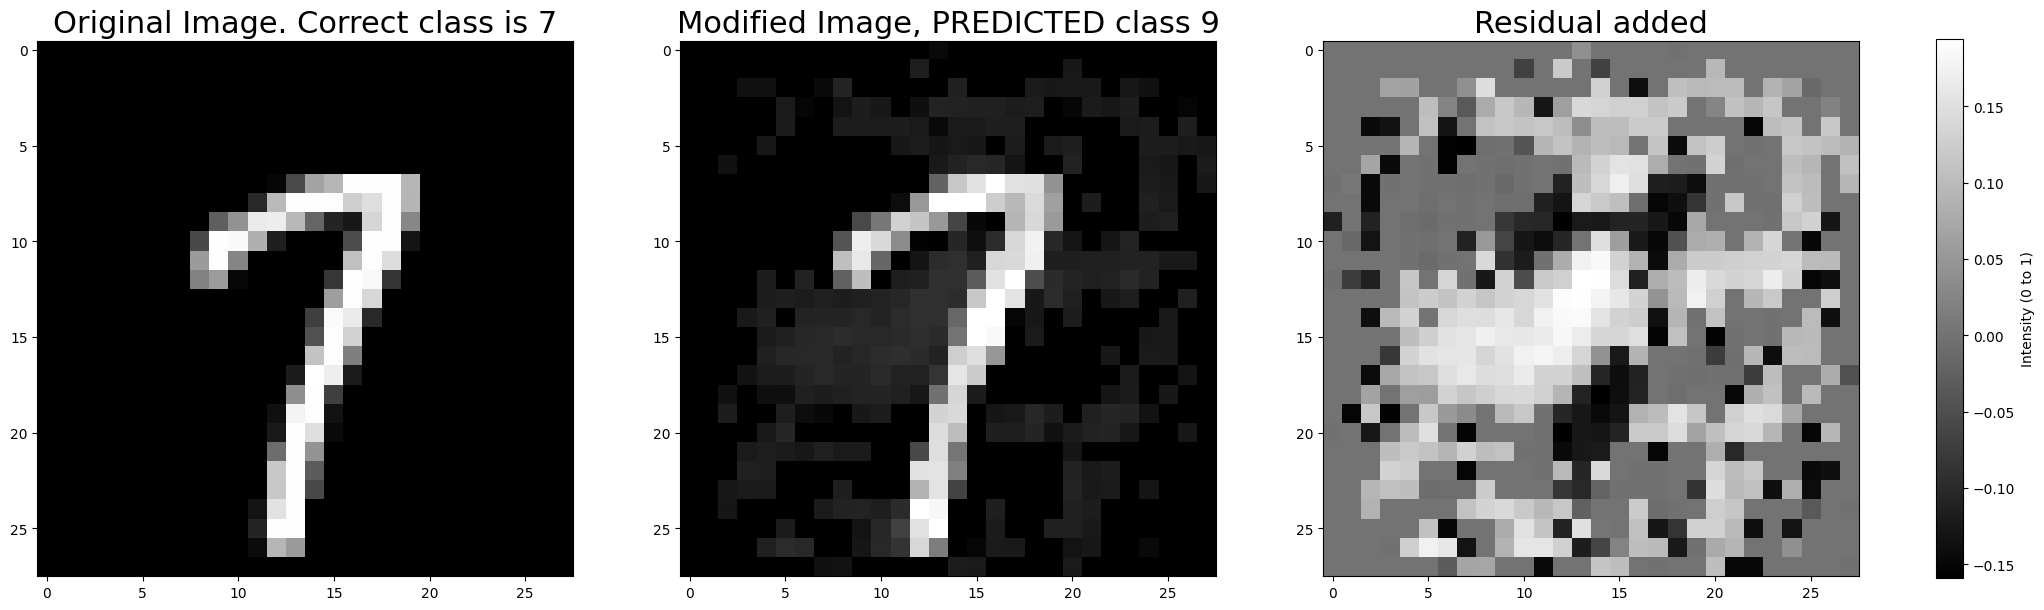

In [20]:
testI = testI.to(device)
r = torch.zeros_like(testI, requires_grad=True)

c = 1e-2  # fixed regularization weight
lr = 1e-2
n_steps = 1000

optimizer = torch.optim.Adam([r], lr=lr)

for step in range(n_steps):
    optimizer.zero_grad()

    x_r = torch.clamp(testI + r, 0, 1)
    logits = model(x_r)

    # same loss as before
    target = logits[0, l]
    others = torch.cat([logits[0, :l], logits[0, l + 1 :]])
    loss_cls = torch.clamp(others.max() - target, min=0)

    loss_reg = torch.norm(r, p=2)
    loss = c * loss_reg + loss_cls

    loss.backward()
    optimizer.step()

with torch.no_grad():
    pred = model(torch.clamp(testI + r, 0, 1)).argmax(dim=1)

print("Predicted label:", pred.item())
print("||r||₂ =", torch.norm(r, p=2))
plot_results(
    testI,
    r,
    torch.clamp(testI + r, 0, 1),
    testY,
    torch.tensor(l) if isinstance(l, int) else l,
    fail=(pred != l),
)


<font color='green'>

When fixing the value of c and optimizing only the perturbation r, Adam converges reliably in most cases. With a well-chosen learning rate and regularization weight, the attack successfully reaches the target class while keeping the perturbation relatively small. The resulting adversarial images remain visually close to the original ones, indicating that this approach works properly in practice, although it is sensitive to hyper-parameter tuning.


Jointly optimizing both r and c leads to unstable behavior. The optimizer tends to decrease c to reduce the influence of the regularization term, which results in excessively large perturbations. This produces degenerate solutions and is therefore not recommended.

The parameter c should be fixed or tuned externally rather than optimized jointly with r. A moderate value of c offers the best trade-off between attack success and perturbation size. Neither minimizing nor maximizing c during optimization is appropriate.

</font>


# Fast Gradient Sign Attack (FGSM)

Another famous method to create adversarial examples is Fast Gradient Sign Attack (FGSM). Let $\theta$ be the parameters of a model, x the input image to the model, y its class and J(θ, x, y) the cost used to train the neural network. Usually, when training a model, we compute the gradient of the cost function with respect to the parameters of the model and update them based on the oppositve (i.e., negative) direction of the gradient to decrease the loss. Here, we can replicate the same reasoning but using the pixel values of the input image instead than the model's parameters and using the gradient direction (i.e., positve) to actually maximize the loss. The idea is thus to modify the pixel values so that the loss is maximized and not minimized. In this way, the perturbation should change the image so that it will be misclassified by the model. In order to keep the changes small, possibly imperceptible to naked eye, we only use the sign of the gradient and multiply it by a small $\epsilon$ value. Mathematically, the adversarial example is estimated using:
 $$x_r =x + \epsilon \text{sign}(\Delta_x J(\theta, x, y))$$

 The gradient can easily be computed using backpropagation (Adam).


[*]` Ian J. Goodfellow, Jonathon Shlens & Christian Szegedy Explaining and harnessing adversarial examples. ICLR. 2015`

Let's load an image.

In [21]:
# Parameters
index = 10
testI, testY = mnist_test.__getitem__(index)
X = testI.unsqueeze(0).to(device)
print(X.shape)
X.requires_grad = True  # Important for attack
Y = torch.tensor([testY]).to(device)

torch.Size([1, 1, 28, 28])


And plot it.

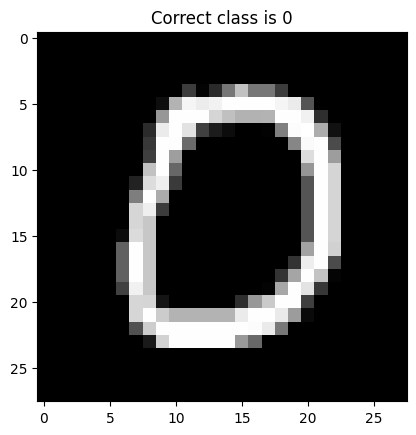

In [22]:
fig = plt.imshow(testI.squeeze(), interpolation="nearest", cmap=plt.cm.gray)
plt.title(f"Correct class is {testY}")
plt.show()

Complete the code by fixing a `eps`value.

Original Class: 0, Perturbed Class: 0
Optimization failed
Norm Perturbation |r|: 78.39937591552734


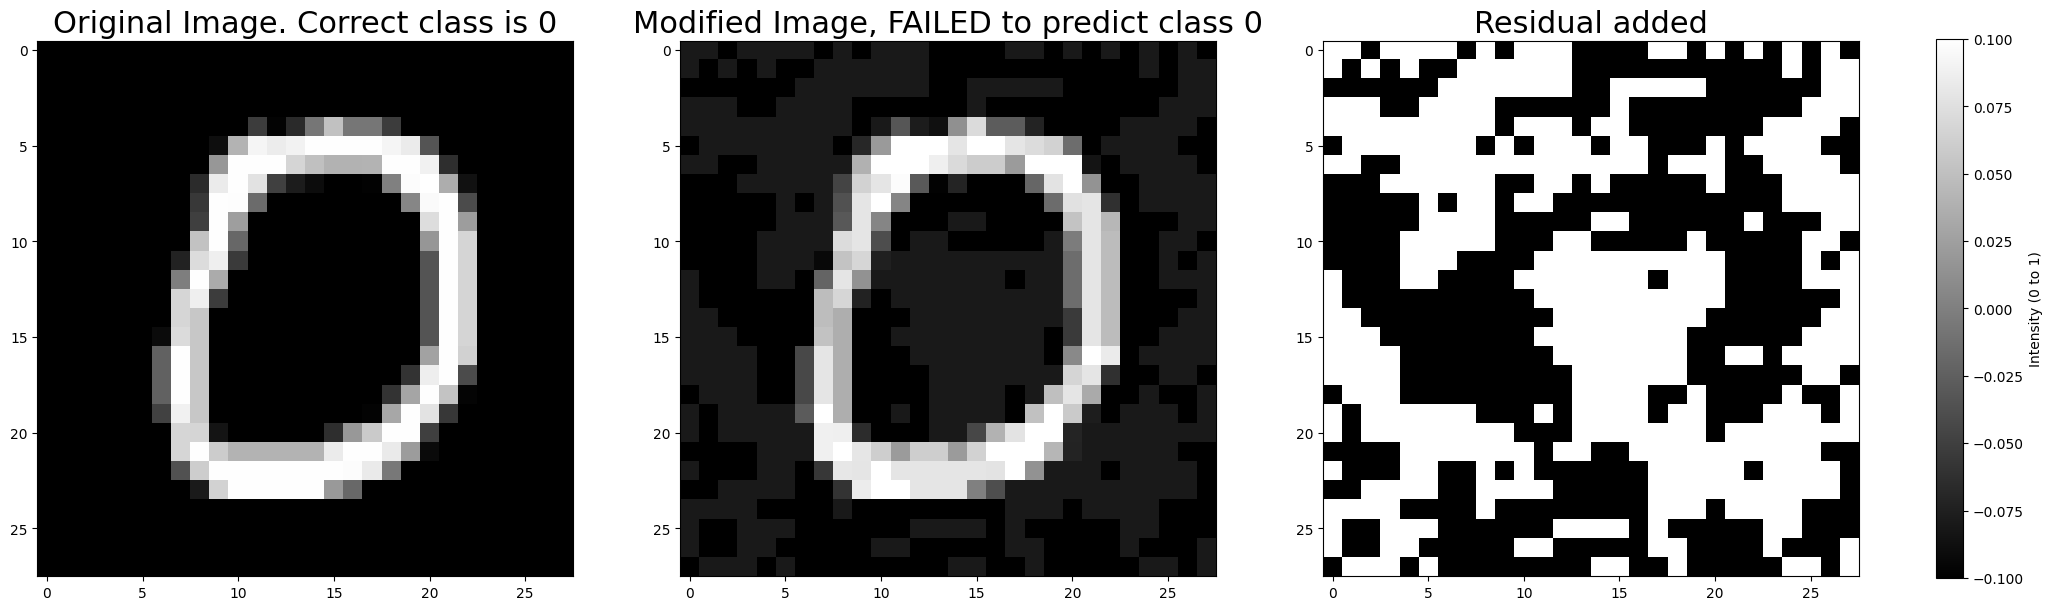

In [23]:
eps = 0.1  # perturbation size

# Forward pass
pred_original = model(X)
original_class = pred_original.argmax(dim=1)

# Compute loss (untargeted FGSM)
cost = F.cross_entropy(pred_original, original_class)

# Zero existing gradients
model.zero_grad()

# Backward pass
cost.backward()

# FGSM attack
Xr = X + eps * X.grad.data.sign()
Xr = torch.clamp(Xr, 0, 1)

# Re-classify perturbed image
pred_perturbed = model(Xr)
perturbed_class = pred_perturbed.argmax(dim=1)

# Print results
print(f"Original Class: {original_class.item()}, Perturbed Class: {perturbed_class.item()}")

r = eps * X.grad.data.sign()

if original_class.item() == perturbed_class.item():
    print("Optimization failed")
    print(f"Norm Perturbation |r|: {torch.norm(r, p=1)}")
    plot_results(X, r, Xr, testY, perturbed_class, fail=True)
else:
    print("Optimization successful")
    print(f"Norm Perturbation |r|: {torch.norm(r, p=1)}")
    plot_results(X, r, Xr, testY, perturbed_class, fail=False)


Now, to find the best `eps`value, you will code a function and evalute the successful rate for each `eps`value (number of images where an adversarial examples has been successfully created). 

**Question**: What's the best `eps`value ? Are the changes imperceptible to a naked human eye ?

Using epsilon: 0.2 we succesfully create 95.39 % adversariale examples


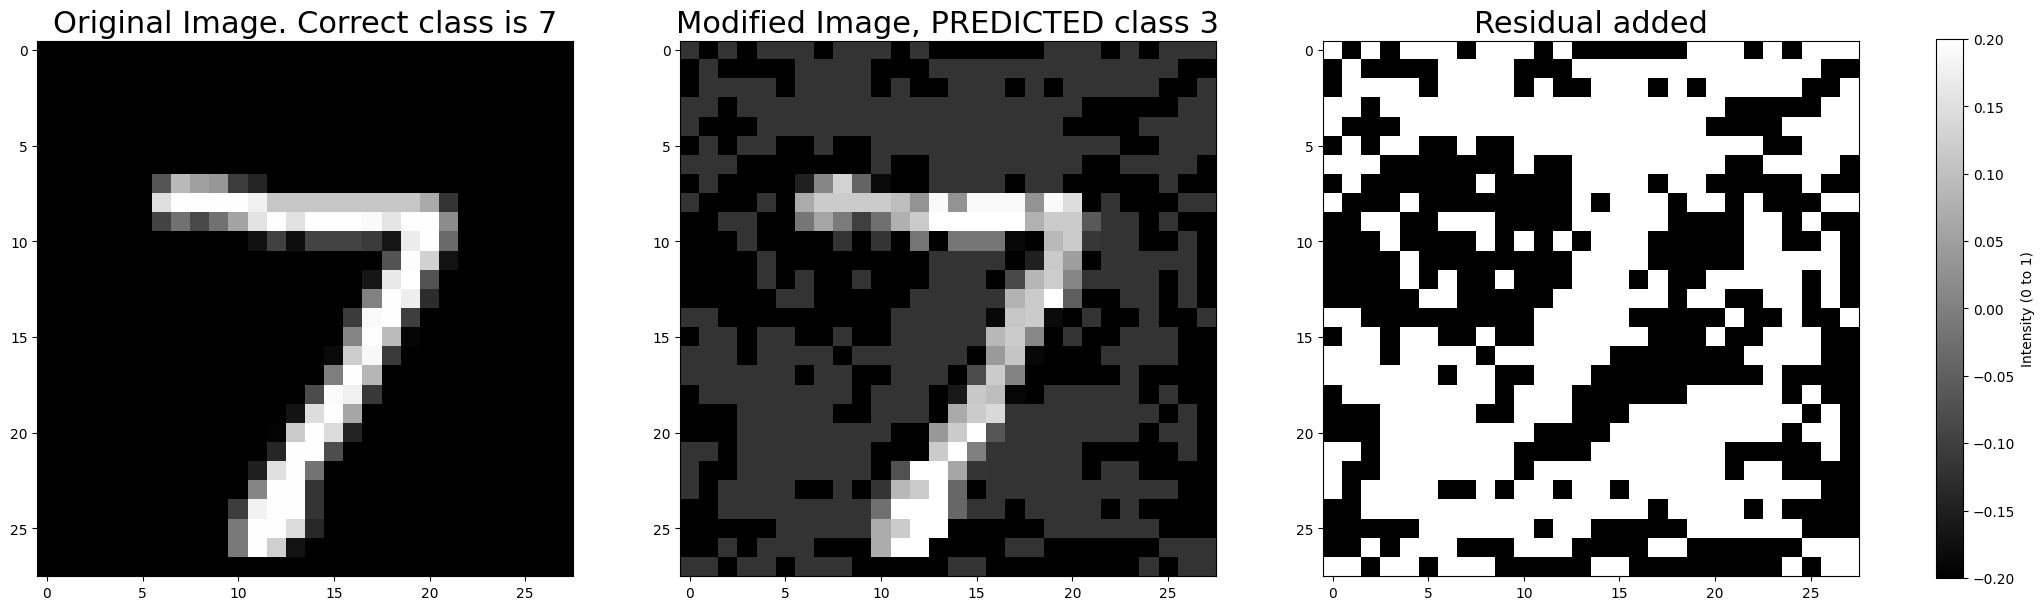

In [24]:
from tqdm import tqdm


def fgsm_attack(X, Y, model, loss_model, eps):
    X = X.clone().detach().requires_grad_(True)

    # Forward
    pred = model(X)
    original_class = pred.argmax(dim=1)

    loss = loss_model(pred, Y.unsqueeze(0))

    # Backward
    model.zero_grad()
    loss.backward()

    # Perturbation
    r = eps * X.grad.data.sign()
    Xr = torch.clamp(X + r, 0, 1)

    # Re-classify
    pred_perturbed = model(Xr)
    perturbed_class = pred_perturbed.argmax(dim=1)

    return Xr, original_class, perturbed_class, r


# Accuracy counter
adv_examples = []
succes = 0
total = 0
eps = 0.2  # perturbation size

# Loop over all examples in test set
for X_batch, Y_batch in test_loader:  # Iterate through batches
    for X, Y in zip(X_batch, Y_batch):
        X = X.unsqueeze(0).to(device)
        Y = Y.to(device)

        Xr, original_class, perturbed_class, r = fgsm_attack(X, Y, model, loss_model, eps)

        total += 1
        if original_class.item() != perturbed_class.item():
            succes += 1
            adv_examples.append((X, r, Xr, Y, perturbed_class))

# Calculate final accuracy for this epsilon
Adv_acc = 100 * succes / total
print(f"Using epsilon: {eps} we succesfully create {Adv_acc} % adversariale examples")

# Plot one example
index = 0
X, r, Xr, Y, perturbed_class = adv_examples[index]
plot_results(X, r, Xr, Y, perturbed_class, fail=False)

In [25]:
eps_grid = [0.0, 0.01, 0.03, 0.05, 0.1, 0.15, 0.2]

results = {}
examples_per_eps = {}

loss_model = torch.nn.CrossEntropyLoss()

for eps in eps_grid:
    succes = 0
    total = 0
    adv_example = None

    for X_batch, Y_batch in test_loader:
        for X, Y in zip(X_batch, Y_batch):
            X = X.unsqueeze(0).to(device)
            Y = Y.to(device)

            Xr, original_class, perturbed_class, r = fgsm_attack(X, Y, model, loss_model, eps)

            total += 1
            if original_class.item() != perturbed_class.item():
                succes += 1
                if adv_example is None:
                    adv_example = (X, r, Xr, Y, perturbed_class)

    success_rate = 100 * succes / total
    results[eps] = success_rate
    examples_per_eps[eps] = adv_example

    print(f"eps={eps:.3f} - success rate = {success_rate:.2f}%")


eps=0.000 - success rate = 0.00%
eps=0.010 - success rate = 1.47%
eps=0.030 - success rate = 7.63%
eps=0.050 - success rate = 21.42%
eps=0.100 - success rate = 71.93%
eps=0.150 - success rate = 91.06%
eps=0.200 - success rate = 95.39%


No adversarial example found for eps=0.0
epsilon = 0.01


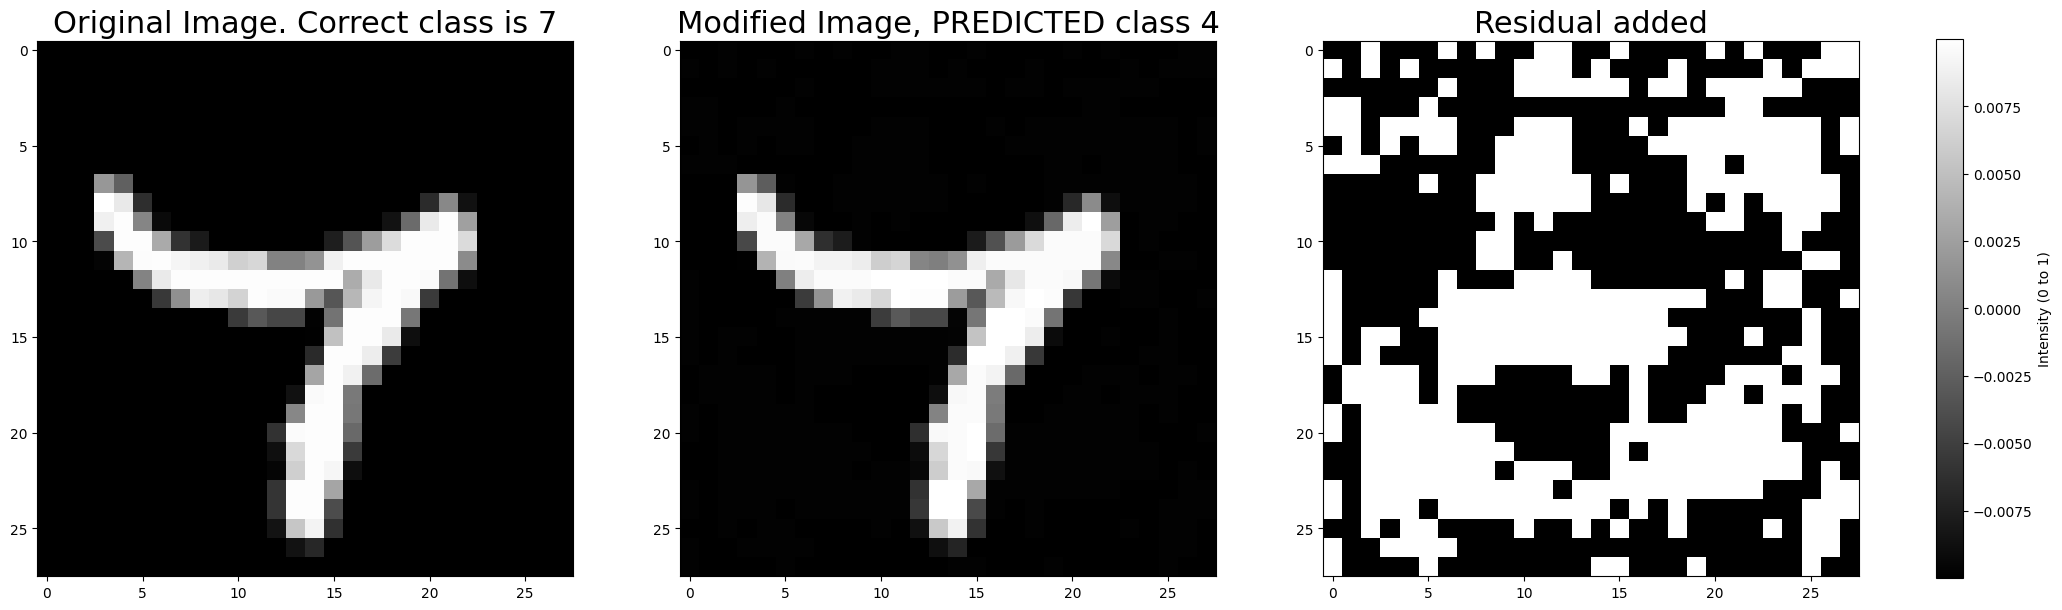

epsilon = 0.03


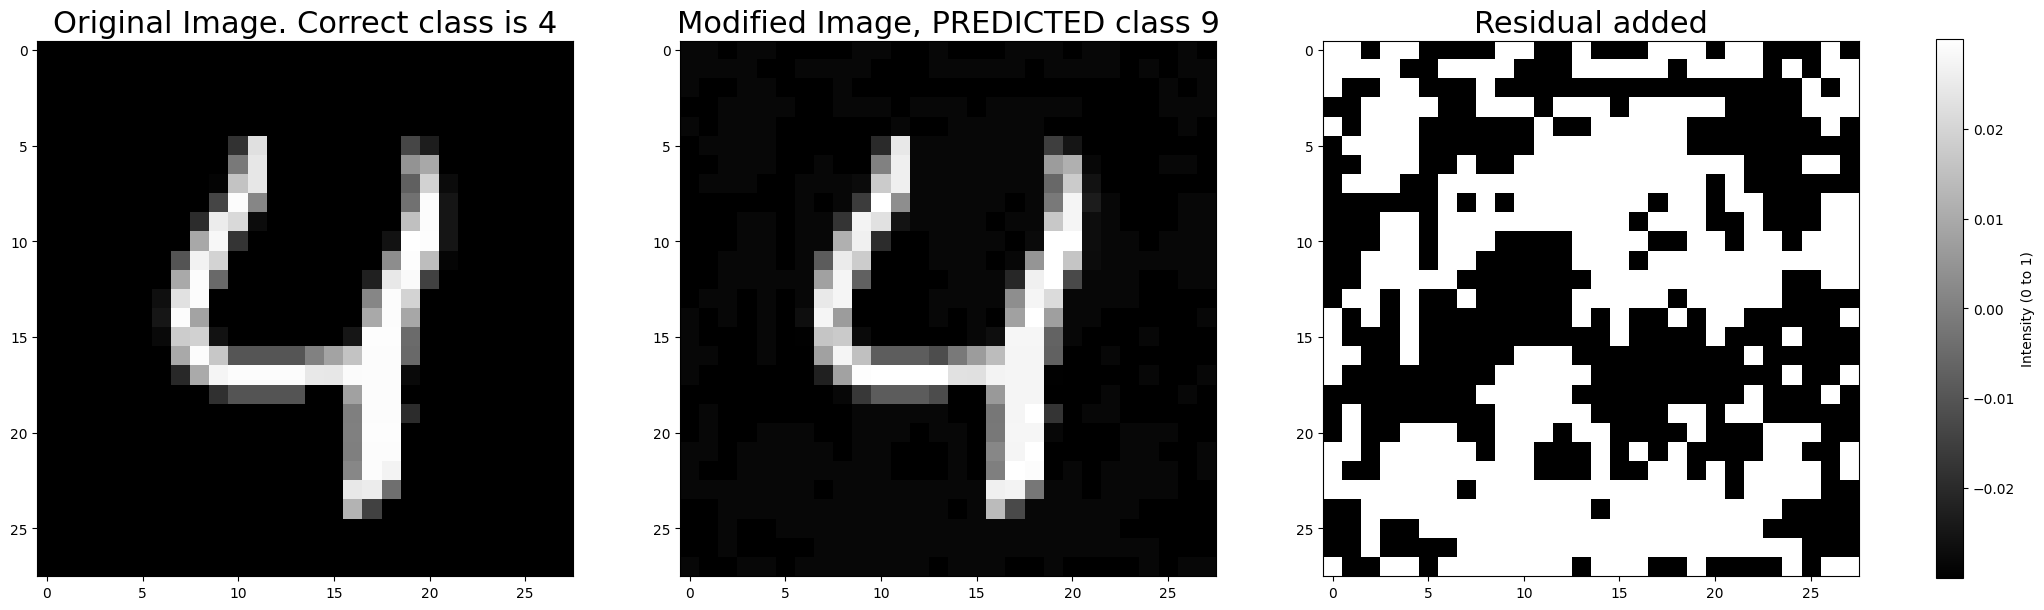

epsilon = 0.05


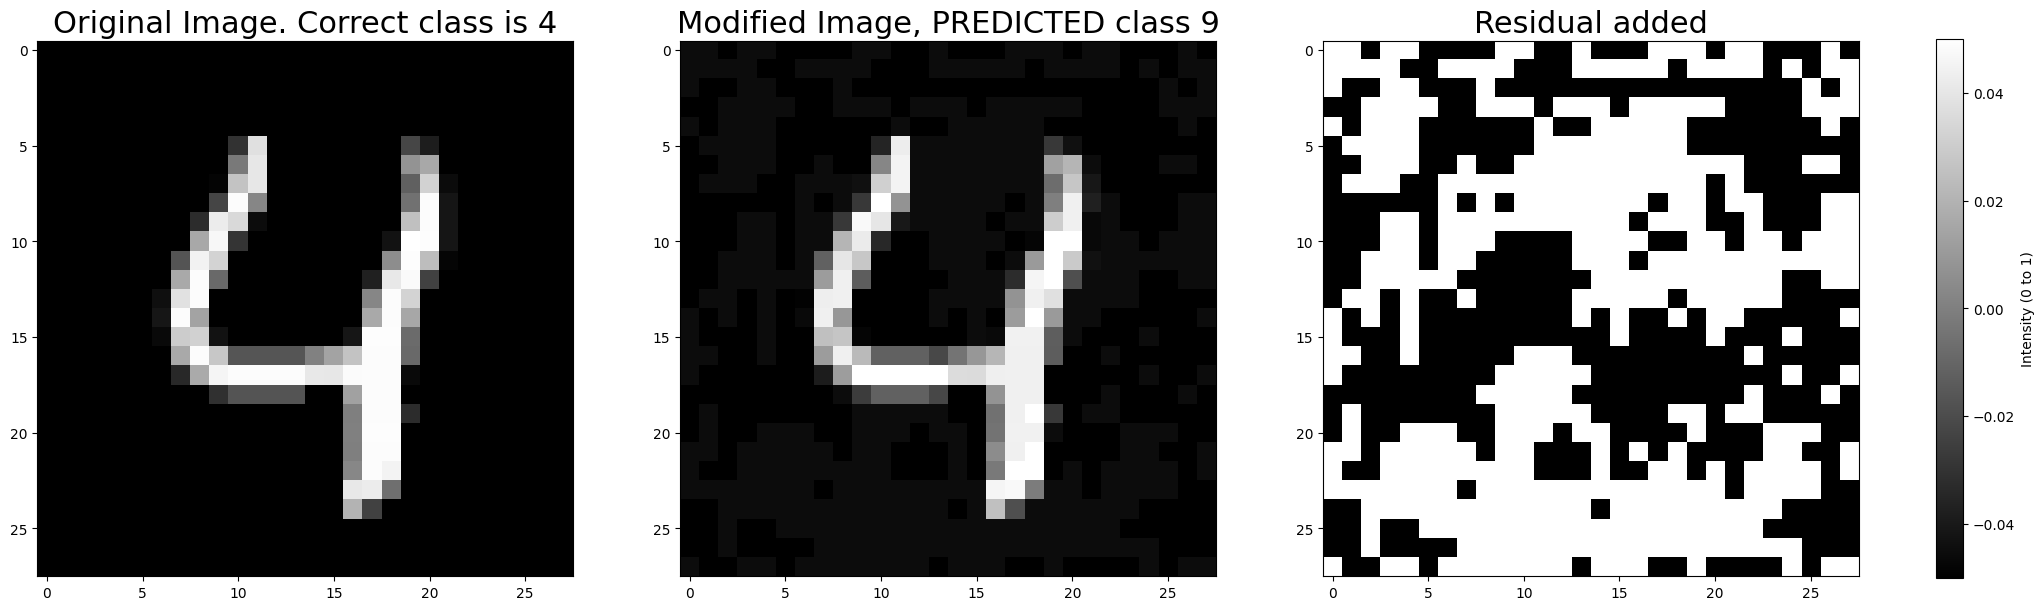

epsilon = 0.1


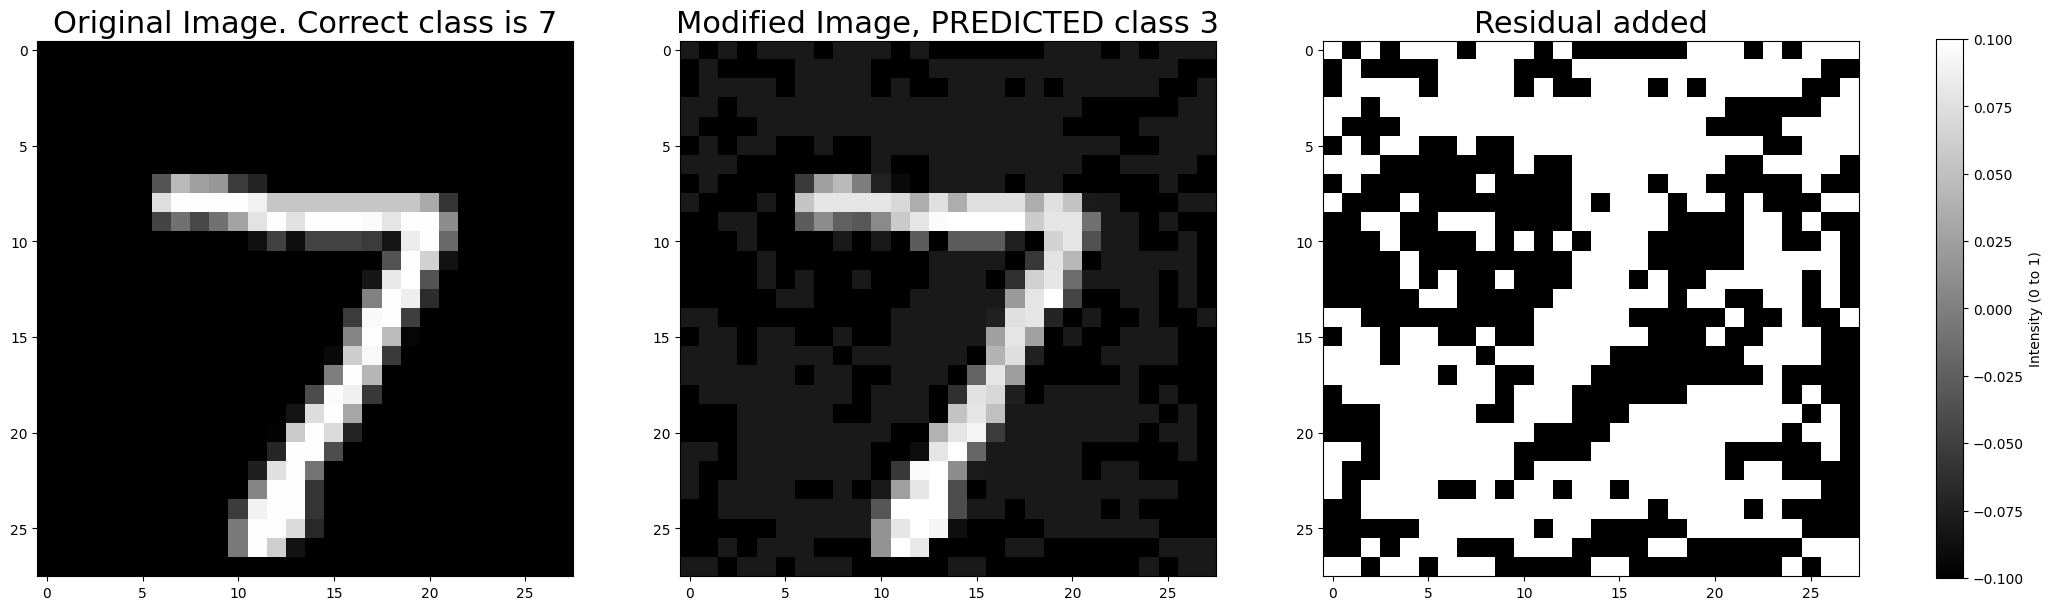

epsilon = 0.15


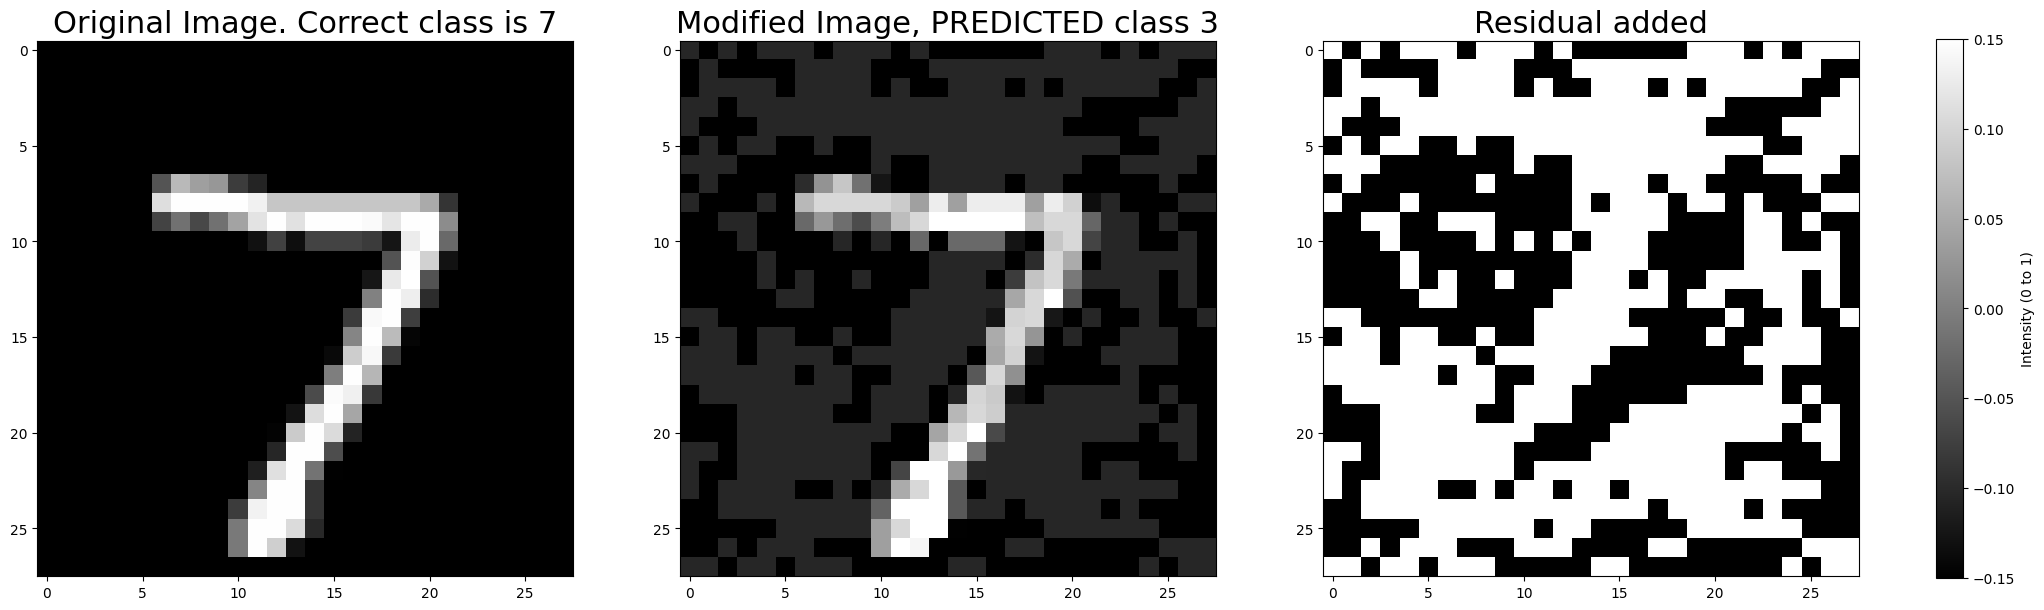

epsilon = 0.2


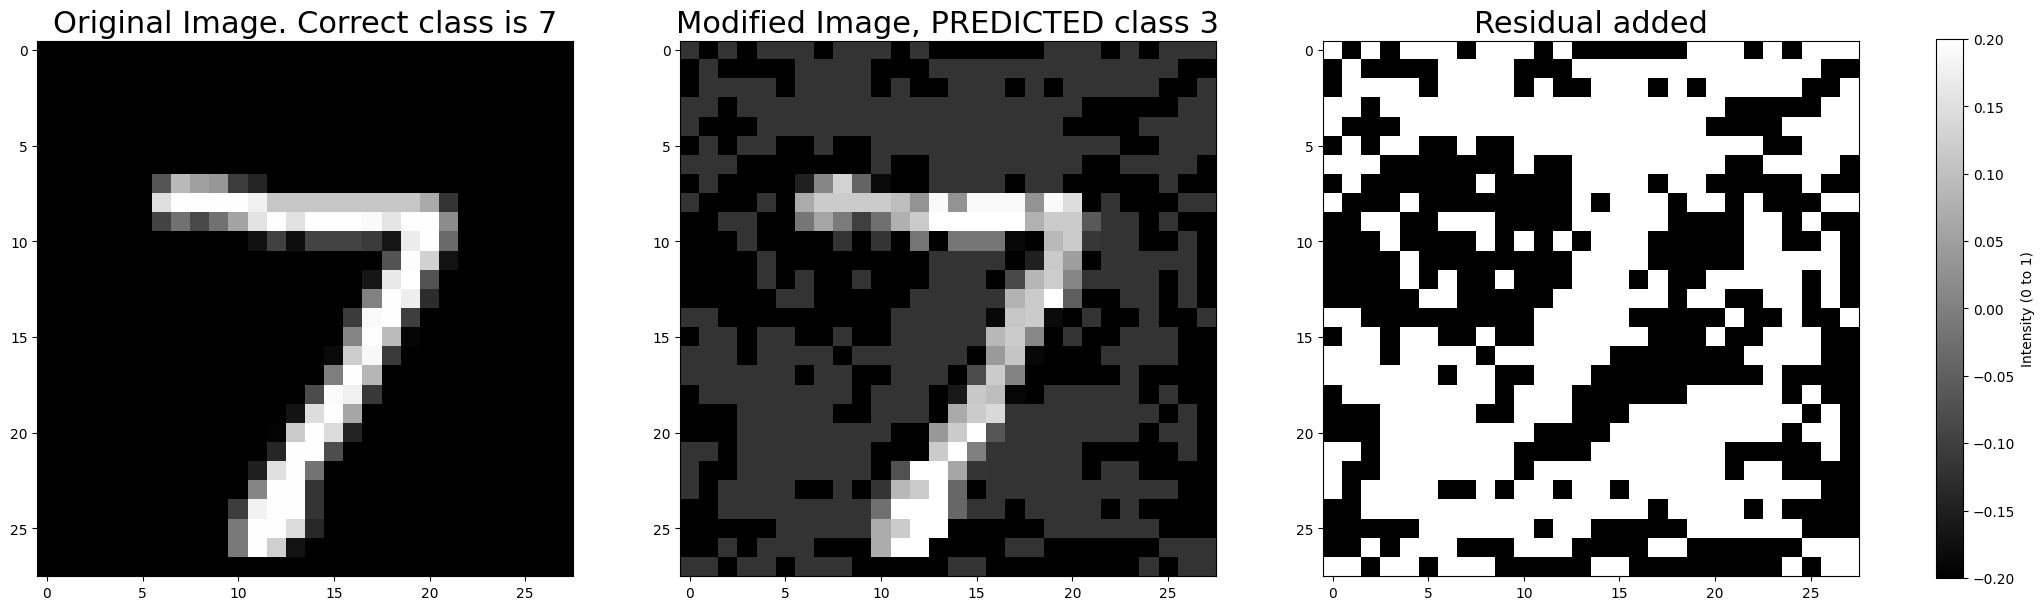

In [26]:
for eps in eps_grid:
    example = examples_per_eps[eps]
    if example is None:
        print(f"No adversarial example found for eps={eps}")
        continue

    X, r, Xr, Y, perturbed_class = example
    print(f"epsilon = {eps}")
    plot_results(X, r, Xr, Y, perturbed_class, fail=False)


<div style="color: green;">
Evaluating FGSM over a grid of perturbation magnitudes epsilon and measureing the attack success rate.
As epsilon increases, the success rate rises monotonically, from 0% at epsilon = 0 to about 31% at epsilon = 0.2.
This confirms that larger perturbations make adversarial examples easier to generate, at the cost of stronger visual distortion.
For this model, epsilon in the range 0.1 provides the best trade-off between attack effectiveness and perceptual quality, while smaller epsilon values remain mostly ineffective.
</div>
